## Проектная работа
Рынок заведений общественного питания Москвы


## Описание проекта
- Инвесторы из фонда «Shut Up and Take My Money» решили попробовать себя в новой области и открыть заведение общественного питания в Москве. Заказчики ещё не знают, что это будет за место: кафе, ресторан, пиццерия, паб или бар, — и какими будут расположение, меню и цены.
- Для начала они просят вас — аналитика — подготовить исследование рынка Москвы, найти интересные особенности и презентовать полученные результаты, которые в будущем помогут в выборе подходящего инвесторам места.
- Постарайтесь сделать презентацию информативной и лаконичной. Её структура и оформление сильно влияют на восприятие информации читателями вашего исследования. Выбирать инструменты (matplotlib, seaborn и другие) и типы визуализаций вы можете самостоятельно.
- Вам доступен датасет с заведениями общественного питания Москвы, составленный на основе данных сервисов Яндекс Карты и Яндекс Бизнес на лето 2022 года. Информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена пользователями или найдена в общедоступных источниках. Она носит исключительно справочный характер.

## Описание данных

Файл moscow_places.csv:
 - name — название заведения;
 - address — адрес заведения;
 - category — категория заведения, например «кафе», «пиццерия» или «кофейня»;
 - hours — информация о днях и часах работы;
 - lat — широта географической точки, в которой находится заведение;
 - lng — долгота географической точки, в которой находится заведение;
 - rating — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
 - price — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
 - avg_bill — строка, которая хранит среднюю стоимость заказа в виде диапазона, например:
«Средний счёт: 1000–1500 ₽»;
«Цена чашки капучино: 130–220 ₽»;
«Цена бокала пива: 400–600 ₽».
и так далее;
 - middle_avg_bill — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
 - middle_coffee_cup — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.
 - chain — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
0 — заведение не является сетевым
1 — заведение является сетевым
 - district — административный район, в котором находится заведение, например Центральный административный округ;
 - seats — количество посадочных мест.

## Проделаем работу:
 - Шаг 1. Загрузите данные и изучите общую информацию
 - Шаг 2. Выполните предобработку данных
 - Шаг 3. Анализ данных
 - Шаг 4. Детализируем исследование: открытие кофейни
 - Шаг 5. Подготовка презентации
 - Шаг 6. Сформируем общий вывод

## Импортируем библиотеки

In [1]:
# импортируем нужные библиотеки
import pandas as pd
import scipy.stats as stats
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
sns.set(rc={'figure.figsize':(10, 8)})
import requests

from scipy import stats as st
import warnings

from plotly import graph_objects as go
import math as mth

import os

import plotly.express as px


import folium
from folium import Map, Choropleth, Marker
from folium.plugins import MarkerCluster
from folium.features import CustomIcon

warnings.filterwarnings("ignore")  # бережем глаза от ненужных предупреждений

In [2]:
pd.set_option('display.max_columns', None)
pd.options.display.float_format = '{:,.2f}'.format

## - Шаг 1. Загрузите данные и изучите общую информацию

In [3]:
# проверяем пути к файлам на их наличие

pth1 = '/datasets/moscow_places.csv'


if os.path.exists(pth1):
    query_1 = pd.read_csv(pth1)
else:
    print('Something is wrong')

In [4]:
# загружаем данные
try:
    df = pd.read_csv(pth1)
except:
    df = pd.read_csv('https://code.s3.yandex.net/datasets/moscow_places.csv')


In [5]:
# выведим на экран
df.head(5)

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.48,5.00,NaN,NaN,NaN,NaN,0,NaN
1,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.48,4.50,выше среднего,Средний счёт:1500–1600 ₽,"1,550.00",NaN,0,4.00
2,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.89,37.53,4.60,средние,Средний счёт:от 1000 ₽,"1,000.00",NaN,0,45.00
3,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.88,37.49,5.00,NaN,Цена чашки капучино:155–185 ₽,NaN,170.00,0,NaN
4,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.45,5.00,средние,Средний счёт:400–600 ₽,500.00,NaN,1,148.00


In [6]:
# выведим последних 5 значений
df.tail(5)

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats
8401,Суши Мания,кафе,"Москва, Профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",55.67,37.55,4.40,NaN,NaN,NaN,NaN,0,86.00
8402,Миславнес,кафе,"Москва, Пролетарский проспект, 19, корп. 1",Южный административный округ,"ежедневно, 08:00–22:00",55.64,37.66,4.80,NaN,NaN,NaN,NaN,0,150.00
8403,Самовар,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",55.65,37.74,3.90,NaN,Средний счёт:от 150 ₽,150.00,NaN,0,150.00
8404,Чайхана Sabr,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",55.65,37.74,4.20,NaN,NaN,NaN,NaN,1,150.00
8405,Kebab Time,кафе,"Москва, Россошанский проезд, 6",Южный административный округ,"ежедневно, круглосуточно",55.60,37.60,3.90,NaN,NaN,NaN,NaN,0,12.00


In [7]:
# просмотр основоной информации
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   lat                8406 non-null   float64
 6   lng                8406 non-null   float64
 7   rating             8406 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
 12  chain              8406 non-null   int64  
 13  seats              4795 non-null   float64
dtypes: float64(6), int64(1), object(7)
memory usage: 919.5+ KB


In [8]:
# df.isna().sum()

### Вывод шаг 1
 - Загрузили данные
 - Данные нормальные
 - Сколько заведений представлено? 
    - В данных 8406 заведений
 - Что можно сказать о каждом столбце?
    - Есть заведение не с полной информацие. Не полная информация может быть изза технических ошибок , возможно ручное введение данных.
 
 - Значения какого типа они хранят? 
    - В основном типы данных в текстовом формате

##  - Шаг 2. Выполните предобработку данных

- Изучите, есть ли дубликаты в данных. Поищите пропуски: встречаются ли они, в каких столбцах? Можно ли их обработать или оставить как есть?
- Выполните предобработку данных:
  - Создайте столбец street с названиями улиц из столбца с адресом.
  - Создайте столбец is_24_7 с обозначением, что заведение работает ежедневно и круглосуточно (24/7):
  - логическое значение True — если заведение работает ежедневно и круглосуточно;
  - логическое значение False — в противоположном случае.

In [9]:
# выведим название столбцов
df.columns.tolist()

['name',
 'category',
 'address',
 'district',
 'hours',
 'lat',
 'lng',
 'rating',
 'price',
 'avg_bill',
 'middle_avg_bill',
 'middle_coffee_cup',
 'chain',
 'seats']

In [10]:
# переименнуем столбец
df = df.rename(columns={'number':'number_of_seats'})

In [11]:
# выевдим пропущенные значения
df.isna().sum()

name                    0
category                0
address                 0
district                0
hours                 536
lat                     0
lng                     0
rating                  0
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
chain                   0
seats                3611
dtype: int64

In [12]:
# сделаем строчные буквы в столбцах
df['name'] = df['name'].str.lower()
df['address'] = df['address'].str.lower()
df['avg_bill'] = df['avg_bill'].str.lower()

In [13]:
# проверим дубликаты
df.duplicated().sum()

0

In [14]:
# проверим неявные дубликаты
# дубликатами будем считать совпадения в столбцах с названием и адресом:
df.duplicated(subset = ['name', 'address']).sum()

4

In [15]:
# удалим неявные дубликаты
df = df.drop_duplicates(subset = ['name', 'address']).reset_index(drop=True)

In [16]:
# Создадим столбец street с названиями улиц из столбца с адресом. отберем значение между запяттыми методом split()
df['street'] = df['address'].str.split(', ').str[1]

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Исправила 🙂
</div>

In [17]:
# cоздадим столбец is_24/7 с обозначением, что заведение работает ежедневно и круглосуточно (24/7)
df['is_24_7'] = df['hours'] == 'ежедневно, круглосуточно'

In [18]:
# выведим на экран 
df.head(5)

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,is_24_7
0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.48,5.00,NaN,NaN,NaN,NaN,0,NaN,улица дыбенко,False
1,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.48,4.50,выше среднего,средний счёт:1500–1600 ₽,"1,550.00",NaN,0,4.00,улица дыбенко,False
2,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.89,37.53,4.60,средние,средний счёт:от 1000 ₽,"1,000.00",NaN,0,45.00,клязьминская улица,False
3,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.88,37.49,5.00,NaN,цена чашки капучино:155–185 ₽,NaN,170.00,0,NaN,улица маршала федоренко,False
4,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.45,5.00,средние,средний счёт:400–600 ₽,500.00,NaN,1,148.00,правобережная улица,False


### Вывод шаг 2
 - Название столбцов не изменяли
 - Пропущеные обнаружены, удалять не будем, оставим как есть
     - Пропусков дастаточно много, просто удалить их не получится. осмотрим как их можно восполнить
     - Пропуски в hours, seats правильно заполнить не удастся, так как это индивидуальные данные для каждого заведения.
     - столбец price в разных административных округах имеет разное значение, и заполять пропуски в соответствии со значениями в столбце middle_avg_bill будет некорректным.
     - значения в столбце avg_bill распределены по столбцам middle_avg_bill и middle_coffee_cup.
 - Сделаем строчные буквы в столбцах
 - Обнаружили 4 неявных дубликатов, удалили их, на данные не повлияет
 - Добавили столбец street с названиями улиц из столбца с адресом
 - Добавили столбе is_24/7 с обозначением, что заведение работает ежедневно и круглосуточно (24/7)
 - Типы данных корректные


## - Шаг 3. Анализ данных

### Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по категориям: рестораны, кофейни, пиццерии, бары и так далее. Постройте визуализации. Ответьте на вопрос о распределении заведений по категориям.

,count
category,
кафе,2376
ресторан,2042
кофейня,1413
"бар,паб",764
пиццерия,633
быстрое питание,603
столовая,315
булочная,256


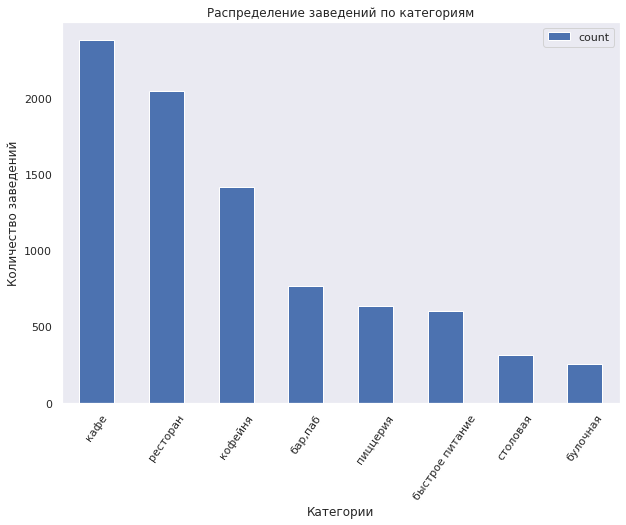

In [19]:
# построим сводную по категориям кол-во
category_count =df.pivot_table(
    index = 'category',
    values = 'name',
    aggfunc = 'count').sort_values(
    by = 'name',
    ascending = False)

# переименнуем столбце
category_count.columns = ['count']

display(category_count)

# построим гистограмму по категориям
category_count.plot(kind = 'bar', figsize=(10, 7))

plt.title('Распределение заведений по категориям')
plt.ylabel('Количество заведений')
plt.xlabel('Категории')
plt.xticks(rotation = 55)
plt.grid()
plt.show()

#### Вывод:
- Максимальное кол-во заведений в категории кафе 2376 шт.
- Минимальное кол-во заведений в категории булочная 256 шт.


### Исследуйте количество посадочных мест в местах по категориям: рестораны, кофейни, пиццерии, бары и так далее. Постройте визуализации. Проанализируйте результаты и сделайте выводы.

возьмем медианное значение

,seats
category,
ресторан,86.00
"бар,паб",82.00
кофейня,80.00
столовая,75.50
быстрое питание,65.00
кафе,60.00
пиццерия,55.00
булочная,50.00


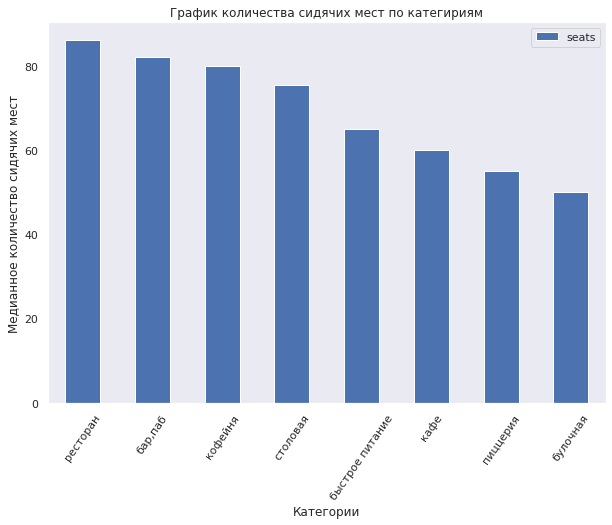

In [20]:
# построим сводную по категориям посадочные места
category_seats = df.pivot_table(
    index = 'category',
    values = 'seats',
    aggfunc = 'median').sort_values(
    by = 'seats',
    ascending = False
)

display(category_seats)

# построим гистограмму по категориям
category_seats.plot(kind = 'bar', figsize=(10, 7))

plt.title('График количества сидячих мест по категириям')
plt.ylabel('Медианное количество сидячих мест')
plt.xlabel('Категории')
plt.xticks(rotation = 55)
plt.grid()
plt.show()

#### Вывод:
- Максимальное медианное кол-во посадочных мест в категории ресторан 86 шт.
- Минимальное медианное кол-во посадочных мест в категории булочная 50 шт.

### Рассмотрите и изобразите соотношение сетевых и несетевых заведений в датасете. Каких заведений больше?

In [21]:
# заменим значения на считаемые 0 и 1 на "несетевые" и "сетевые" соответственно
df['chain'] = df['chain'].replace(0, 'несетевые')
df['chain'] = df['chain'].replace(1, 'сетевые')

In [22]:
# построим сводную
chain = df.pivot_table(
    index = 'chain',
    values = 'name',
    aggfunc = 'count').sort_values(
    by = 'name',
    ascending = False).reset_index()

# переименнуем столбцы
chain.columns = ['chain', 'count']

display(chain)

# постороим соотнашение круговую
fig = go.Figure(data=[go.Pie(labels=chain['chain'], values=chain['count'])])
fig.update_layout(title='Соотношение "сетевых" и "несетевых" заведений')
fig.show()

,chain,count
0,несетевые,5199
1,сетевые,3203


#### Вывод:
- Максимальное кол-во заведений несетевых 5199 шт. 61,9%
- Минимальное кол-во заведений сетевых 3203 шт. 38,1%

### Какие категории заведений чаще являются сетевыми? Исследуйте данные и ответьте на вопрос графиком.

In [23]:
# отфильтруем даанные только по сетевым
chain_category_s = df.query('chain == "сетевые"')

,name
category,
кафе,779
ресторан,729
кофейня,720
пиццерия,330
быстрое питание,232
"бар,паб",168
булочная,157
столовая,88


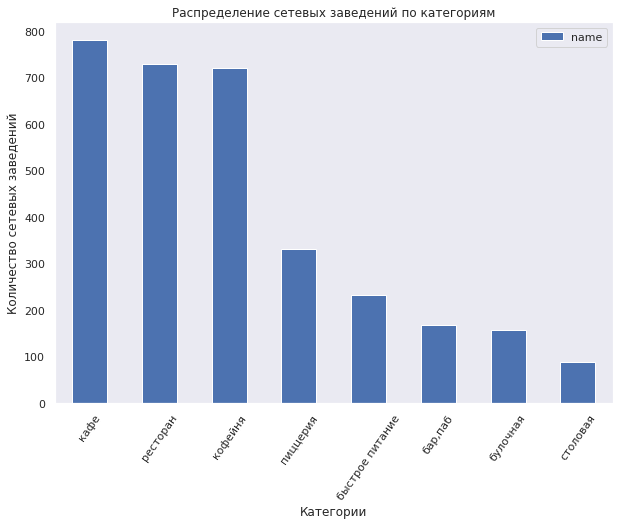

In [24]:
# построим сводную по категориям кол-во
category_count_s = chain_category_s.pivot_table(
    index = 'category',
    values = 'name',
    aggfunc = 'count').sort_values(
    by = 'name',
    ascending = False)

display(category_count_s)

# построим гистограмму по категориям
category_count_s.plot(kind = 'bar', figsize=(10, 7))

plt.title('Распределение сетевых заведений по категориям')
plt.ylabel('Количество сетевых заведений')
plt.xlabel('Категории')
plt.xticks(rotation = 55)
plt.grid()
plt.show()

In [25]:
# переименнуем столбцы
category_count_s.columns = ['count']

# добавим столбец percent % доля от общего кол-ва

category_count_s['percent_in_df'] = category_count_s['count'] / category_count['count'].sum() * 100
category_count_s
display(category_count_s)


,count,percent_in_df
category,,
кафе,779,9.27
ресторан,729,8.68
кофейня,720,8.57
пиццерия,330,3.93
быстрое питание,232,2.76
"бар,паб",168,2.00
булочная,157,1.87
столовая,88,1.05


In [26]:
category_count_s['count_n'] = category_count['count']

In [27]:
display(category_count_s)

,count,percent_in_df,count_n
category,,,
кафе,779,9.27,2376
ресторан,729,8.68,2042
кофейня,720,8.57,1413
пиццерия,330,3.93,633
быстрое питание,232,2.76,603
"бар,паб",168,2.00,764
булочная,157,1.87,256
столовая,88,1.05,315


In [28]:
category_count_s['percent_in_category'] = category_count_s['count'] / category_count_s['count_n']*100

In [29]:
category_count_s.sort_values(
    by = 'count_n',
    ascending = False)

,count,percent_in_df,count_n,percent_in_category
category,,,,
кафе,779,9.27,2376,32.79
ресторан,729,8.68,2042,35.70
кофейня,720,8.57,1413,50.96
"бар,паб",168,2.00,764,21.99
пиццерия,330,3.93,633,52.13
быстрое питание,232,2.76,603,38.47
столовая,88,1.05,315,27.94
булочная,157,1.87,256,61.33


#### Вывод:
- Максимальное кол-во заведений сетевых в категории кафе 779 шт. это 9,27% от всех заведений в данных и 32,79% в этой категории
- Минимальное кол-во заведений сетевых в категории столовая 88 шт. это 1,05% от всех заведений в данных и 61,33 в этой категории

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>дополнила🙂
</div>

### Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Под популярностью понимается количество заведений этой сети в регионе. Постройте подходящую для такой информации визуализацию. Знакомы ли вам эти сети? Есть ли какой-то признак, который их объединяет? К какой категории заведений они относятся?

,name,chain
0,шоколадница,120
1,домино'с пицца,76
2,додо пицца,74
3,one price coffee,71
4,яндекс лавка,69
5,cofix,65
6,prime,50
7,хинкальная,44
8,кофепорт,42
9,кулинарная лавка братьев караваевых,39


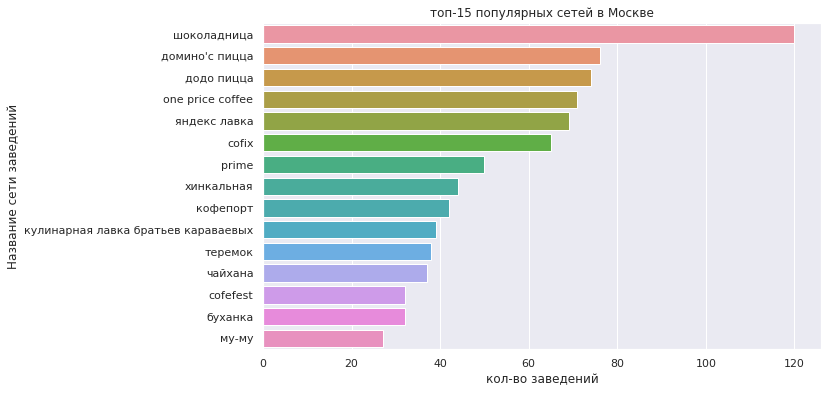

In [30]:
# построим сводную по категориям кол-во
name_count = chain_category_s.pivot_table(
    index = 'name',
    values = 'chain',
    aggfunc = 'count').sort_values(
    by = 'chain',
    ascending = False).reset_index().head(15)

display(name_count)

# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'chain', y = 'name', data = name_count)
plt.title('топ-15 популярных сетей в Москве')
plt.xlabel('кол-во заведений')
plt.ylabel('Название сети заведений')

plt.show()

#### Вывод:
- Максимальное кол-во заведений сетевых в под названием шоколадница 120 шт.
- Минимальное кол-во заведений сетевых в под названием му-му 27 шт.
- Объединяет их всех - это быстрая еда

### Какие административные районы Москвы присутствуют в датасете? Отобразите общее количество заведений и количество заведений каждой категории по районам. Попробуйте проиллюстрировать эту информацию одним графиком.

,district,name
0,Центральный административный округ,2242
1,Северный административный округ,898
2,Южный административный округ,892
3,Северо-Восточный административный округ,890
4,Западный административный округ,850
5,Восточный административный округ,798
6,Юго-Восточный административный округ,714
7,Юго-Западный административный округ,709
8,Северо-Западный административный округ,409


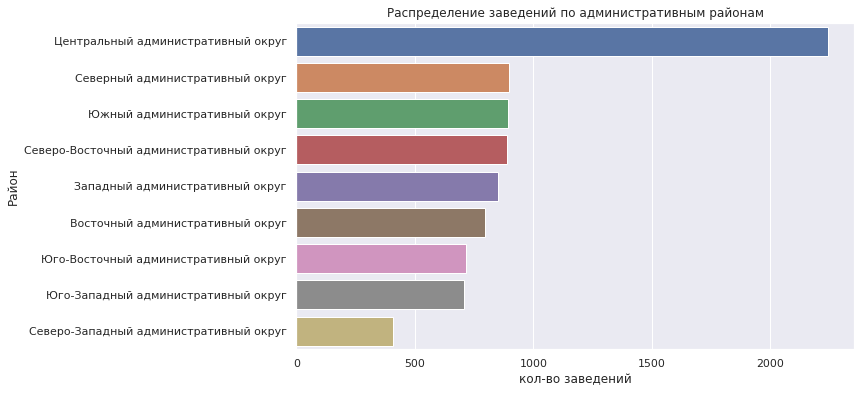

In [31]:
# сводная
district = df.pivot_table(
    index = 'district',
    values = 'name',
    aggfunc = 'count').sort_values(
    by = 'name', ascending = False).reset_index()

display(district)

# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'name', y = 'district', data = district)
plt.title('Распределение заведений по административным районам')
plt.xlabel('кол-во заведений')
plt.ylabel('Район')

plt.show()

In [32]:
# теперь разделим их на категории
district_per_category = df.groupby(
    ['district', 'category']).agg(
    count=('category', 'count')).sort_values(
    by = 'count', ascending = False).reset_index().reset_index()


fig = px.bar(district_per_category.sort_values(by='count', ascending=False), 
             x='count', 
             y='district', 
             color='category')
fig.update_layout(title='Количество заведений каждой категории по районам',
                  xaxis_title='Количество заведений',
                  yaxis_title='Район',
                  height=500,
                  width=1000,
                  xaxis={'categoryorder':'total descending'})
fig.show()

#### Вывод:
- Максимальное кол-во заведений в Центральный административный округ	2242. Большая часть это рестораны
- Минимальное кол-во заведений Северо-Западный административный округ	409


### Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги в разных типах общепита?

In [33]:
# какие рейтинги в датафрейме
df['rating'].unique()

array([5. , 4.5, 4.6, 4.4, 4.7, 4.8, 4.3, 4.9, 4.2, 4.1, 4. , 3.8, 3.9,
       3.7, 3.6, 2.8, 2.7, 3.1, 1.5, 2. , 1.4, 3.3, 3.5, 3.2, 2.9, 3. ,
       3.4, 2.3, 2.2, 2.5, 2.6, 1.7, 1. , 1.1, 2.4, 1.3, 1.2, 2.1, 1.8,
       1.9, 1.6])

,district,name
0,Центральный административный округ,2242
1,Северный административный округ,898
2,Южный административный округ,892
3,Северо-Восточный административный округ,890
4,Западный административный округ,850
5,Восточный административный округ,798
6,Юго-Восточный административный округ,714
7,Юго-Западный административный округ,709
8,Северо-Западный административный округ,409


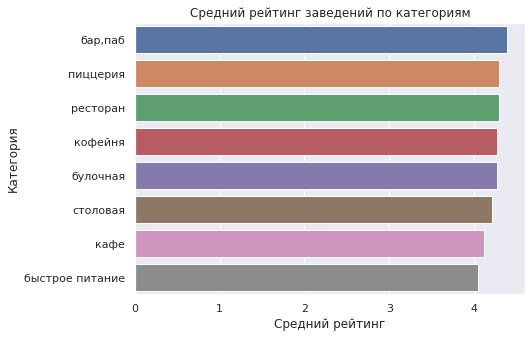

In [34]:
# сводная
ratings = df.pivot_table(
    index = 'category',
    values = 'rating',
    aggfunc = 'mean').sort_values(
    by = 'rating', ascending = False).reset_index()

display(district)

# настройка размера фигуры
plt.figure(figsize=(7, 5))

# построим гистограмму
sns.barplot(x = 'rating', y = 'category', data = ratings)
plt.title('Средний рейтинг заведений по категориям')
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория')

plt.show()

#### Вывод:
- Максимальное рейтинг заведений в бар,паб	4.39 из 5
- Минимальное рейтинг заведений быстрое питание	4.05 из 5

### Постройте фоновую картограмму (хороплет) со средним рейтингом заведений каждого района. Границы районов Москвы, которые встречаются в датасете, хранятся в файле admin_level_geomap.geojson (скачать файл для локальной работы).

In [35]:
# сводная медиальнойе значение рейтингом заведений каждого района
distr_ratings = df.pivot_table(
    index = 'district',
    values = 'rating',
    aggfunc = 'mean').sort_values(
    by = 'rating', ascending = False).reset_index()



distr_ratings

,district,rating
0,Центральный административный округ,4.38
1,Северный административный округ,4.24
2,Северо-Западный административный округ,4.21
3,Южный административный округ,4.18
4,Западный административный округ,4.18
5,Восточный административный округ,4.17
6,Юго-Западный административный округ,4.17
7,Северо-Восточный административный округ,4.15
8,Юго-Восточный административный округ,4.10


In [36]:
# загружаем JSON-файл с границами округов Москвы
try:
    state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson'
except:
    state_geo = '/datasets/admin_level_geomap.geojson'
    
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=distr_ratings,
    columns=['district', 'rating'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.5,
    legend_name='Медианный рейтинг заведений по районам',
).add_to(m)

# выводим карту
m

#### Вывод:
 - Самый высокий рейтинг Центральный административный округ	4.38 из 5
 - Самый низкий рейтинг Юго-Восточный административный округ	4.10 из 5

### Отобразите все заведения датасета на карте с помощью кластеров средствами библиотеки folium.

In [37]:
# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# создаём пустой кластер, добавляем его на карту
marker_cluster = MarkerCluster().add_to(m)

# пишем функцию, которая принимает строку датафрейма,
# создаёт маркер в текущей точке и добавляет его в кластер marker_cluster
def create_clusters(row):
    Marker(
        [row['lat'], row['lng']],
        popup=f"{row['name']} {row['rating']}",
    ).add_to(marker_cluster)

# применяем функцию create_clusters() к каждой строке датафрейма
df.apply(create_clusters, axis=1)

# выводим карту
m

#### Вывод:
 - Все заведения нажодятся в пределах МКАДа

### Найдите топ-15 улиц по количеству заведений. Постройте график распределения количества заведений и их категорий по этим улицам. Попробуйте проиллюстрировать эту информацию одним графиком.

,street,name
0,проспект мира,183
1,профсоюзная улица,122
2,проспект вернадского,108
3,ленинский проспект,107
4,ленинградский проспект,95
5,дмитровское шоссе,88
6,каширское шоссе,77
7,варшавское шоссе,76
8,ленинградское шоссе,70
9,мкад,65


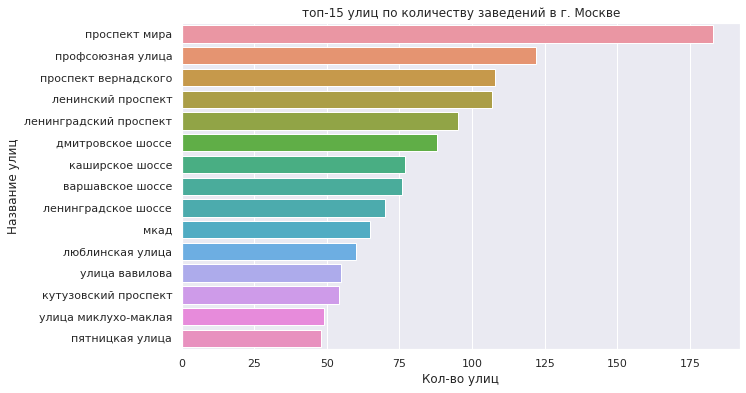

In [38]:
# построим сводную по улицам
street_count = df.pivot_table(
    index = 'street',
    values = 'name',
    aggfunc = 'count').sort_values(
    by = 'name',
    ascending = False).reset_index().head(15)


display(street_count)

# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'name', y = 'street', data = street_count)
plt.title('топ-15 улиц по количеству заведений в г. Москве')
plt.xlabel('Кол-во улиц')
plt.ylabel('Название улиц')

plt.show()

In [39]:
street_list = street_count['street']
street_list

0              проспект мира
1          профсоюзная улица
2       проспект вернадского
3         ленинский проспект
4     ленинградский проспект
5          дмитровское шоссе
6            каширское шоссе
7           варшавское шоссе
8        ленинградское шоссе
9                       мкад
10          люблинская улица
11            улица вавилова
12      кутузовский проспект
13      улица миклухо-маклая
14           пятницкая улица
Name: street, dtype: object

In [40]:
# теперь разделим их на категории
street_per_category = df.query('street in @street_list').groupby(
    ['street', 'category']).agg(
    count=('category', 'count')).sort_values(
    by = 'count', ascending = False).reset_index().reset_index()


fig = px.bar(street_per_category.sort_values(by='count', ascending=False), 
             x='count', 
             y='street', 
             color='category')
fig.update_layout(title='Количество заведений каждой улицы топ-15 по категориям',
                  xaxis_title='Количество заведений',
                  yaxis_title='улица',
                  height=500,
                  width=1000,
                  xaxis={'categoryorder':'total descending'})
fig.show()

#### Вывод:
- Максимальное кол-во заведений на улице - проспект мира	183 шт.
- Минимальное кол-во заведений на улице пятницкая улица	48 шт.

- Первые 5 улиц - это самые длиные улицы в Москве

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>дополнила🙂
</div>

### Найдите улицы, на которых находится только один объект общепита. Что можно сказать об этих заведениях?

In [41]:
# построим сводную улиц с 1 заведением
street_one_place = df.pivot_table(index = 'street', values = 'name', aggfunc = 'count').query("name == 1").reset_index()

display(street_one_place)

,street,name
0,1-й автозаводский проезд,1
1,1-й балтийский переулок,1
2,1-й варшавский проезд,1
3,1-й вешняковский проезд,1
4,1-й голутвинский переулок,1
...,...,...
452,электрический переулок,1
453,юго-западный административный округ,1
454,якиманский переулок,1
455,яковоапостольский переулок,1


In [42]:
# список улиц c 1 заведением
onlyone_street = street_one_place['street']


In [43]:
# отфильруем данные только те улицы где 1 заведение
df_onlyone_street = df.query("street in @onlyone_street")

df_onlyone_street.head(5)

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,is_24_7
15,дом обеда,столовая,"москва, улица бусиновская горка, 2",Северный административный округ,пн-пт 08:30–18:30; сб 10:00–20:00,55.89,37.49,4.10,средние,средний счёт:300–500 ₽,400.00,NaN,несетевые,180.00,улица бусиновская горка,False
21,7/12,кафе,"москва, прибрежный проезд, 7",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.46,4.50,NaN,NaN,NaN,NaN,несетевые,NaN,прибрежный проезд,False
25,в парке вкуснее,кофейня,"москва, парк левобережный",Северный административный округ,"ежедневно, 10:00–21:00",55.88,37.46,4.30,NaN,NaN,NaN,NaN,сетевые,NaN,парк левобережный,False
58,coffeekaldi's,кофейня,"москва, угличская улица, 13, стр. 8",Северо-Восточный административный округ,"ежедневно, 09:00–22:00",55.90,37.57,4.10,средние,средний счёт:500–800 ₽,650.00,NaN,сетевые,NaN,угличская улица,False
60,чебуречная история,кофейня,"москва, ландшафтный заказник лианозовский",Северо-Восточный административный округ,"ежедневно, 10:00–22:00",55.90,37.57,4.90,NaN,NaN,NaN,NaN,сетевые,NaN,ландшафтный заказник лианозовский,False


,category,name
0,кафе,159
1,ресторан,93
2,кофейня,84
3,"бар,паб",39
4,столовая,36
5,быстрое питание,23
6,пиццерия,15
7,булочная,8


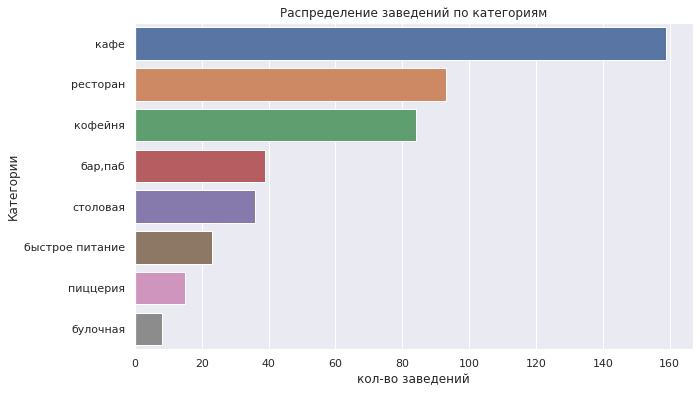

In [44]:
# построим сводную 
df_onlyone_street_cat = df_onlyone_street.pivot_table(
    index = 'category',
    values = 'name',
    aggfunc = 'count').sort_values(by = 'name', ascending = False).reset_index().head(15)

display(df_onlyone_street_cat)

# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'name', y = 'category', data = df_onlyone_street_cat)
plt.title('Распределение заведений по категориям')
plt.xlabel('кол-во заведений')
plt.ylabel('Категории')

plt.show()

По категориям максимальное кол-во в кафе минимальное булочные

,district,name
0,Центральный административный округ,145
1,Северо-Восточный административный округ,55
2,Восточный административный округ,52
3,Северный административный округ,51
4,Южный административный округ,43
5,Юго-Восточный административный округ,39
6,Западный административный округ,35
7,Северо-Западный административный округ,19
8,Юго-Западный административный округ,18


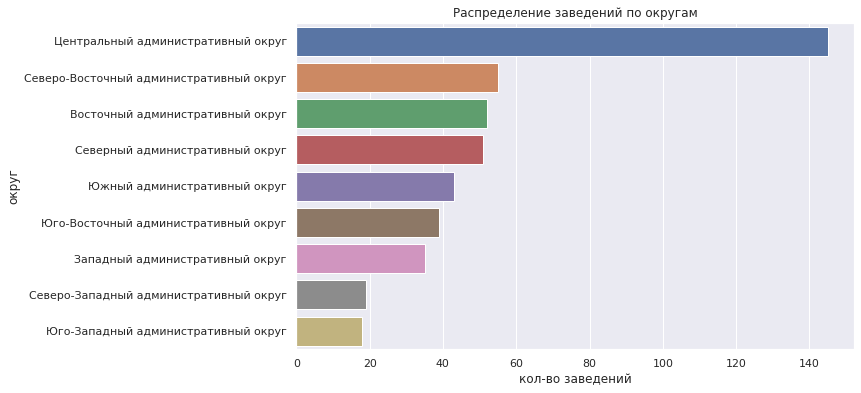

In [45]:
# построим сводную 
df_onlyone_street_dis = df_onlyone_street.pivot_table(
    index = 'district',
    values = 'name',
    aggfunc = 'count').sort_values(by = 'name', ascending = False).reset_index().head(15)

display(df_onlyone_street_dis)

# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'name', y = 'district', data = df_onlyone_street_dis)
plt.title('Распределение заведений по округам')
plt.xlabel('кол-во заведений')
plt.ylabel('округ')

plt.show()

По округам максимальное кол-во в центре, минимальное на юго западе

In [46]:
# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# создаём пустой кластер, добавляем его на карту
marker_cluster = MarkerCluster().add_to(m)

# пишем функцию, которая принимает строку датафрейма,
# создаёт маркер в текущей точке и добавляет его в кластер marker_cluster
def create_clusters(row):
    Marker(
        [row['lat'], row['lng']],
        popup=f"{row['name']} {row['rating']}",
    ).add_to(marker_cluster)

# применяем функцию create_clusters() к каждой строке датафрейма
df_onlyone_street.apply(create_clusters, axis=1)

# выводим карту
m

In [47]:
# построим пирог сетеве заведения и не сетевые
chain_onlyone = df_onlyone_street.pivot_table(
    index = 'chain',
    values = 'name',
    aggfunc = 'count').sort_values(by = 'name', ascending = False).reset_index()

chain_onlyone.columns = ['chain', 'count']
fig = go.Figure(data=[go.Pie(labels=chain_onlyone['chain'], values=chain_onlyone['count'])])
fig.update_layout(title='Соотношение "сетевых" и "несетевых" заведений')
fig.show()

#### Вывод:
 - Найдите улицы, на которых находится только один объект общепита. Что можно сказать об этих заведениях?
   - Заведений 457 шт
   - Заведения расположены равномерно по карте москвы
   - По категориям больше всего кафе 159 шт
   - По округам больше всего находится заведенй в центре 153 шт.
   - Распределение больше несетевых 70,9%, а сетевых 29,1%


### Значения средних чеков заведений хранятся в столбце middle_avg_bill. Эти числа показывают примерную стоимость заказа в рублях, которая чаще всего выражена диапазоном. Посчитайте медиану этого столбца для каждого района. Используйте это значение в качестве ценового индикатора района. Постройте фоновую картограмму (хороплет) с полученными значениями для каждого района. Проанализируйте цены в центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях?

In [48]:
# построим групировку что бы ввывести медианное значение
district_median_middle_avg_bill = df.groupby(
    'district').agg(median_middle_avg_bill=(
    'middle_avg_bill', 'median')).sort_values(
    by='median_middle_avg_bill', ascending=False).reset_index()

district_median_middle_avg_bill

,district,median_middle_avg_bill
0,Западный административный округ,"1,000.00"
1,Центральный административный округ,"1,000.00"
2,Северо-Западный административный округ,700.00
3,Северный административный округ,650.00
4,Юго-Западный административный округ,600.00
5,Восточный административный округ,575.00
6,Северо-Восточный административный округ,500.00
7,Южный административный округ,500.00
8,Юго-Восточный административный округ,450.00


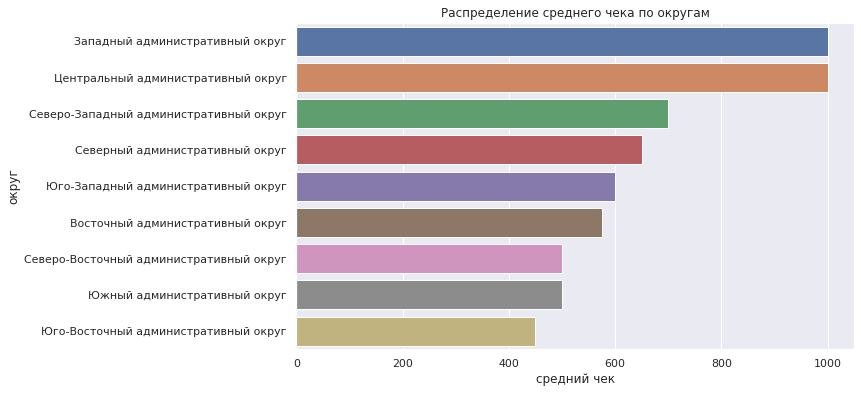

In [49]:
# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'median_middle_avg_bill', y = 'district', data = district_median_middle_avg_bill)
plt.title('Распределение среднего чека по округам')
plt.xlabel('средний чек')
plt.ylabel('округ')

plt.show()

In [50]:
# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=district_median_middle_avg_bill,
    columns=['district', 'median_middle_avg_bill'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Медианный средний чек заведений по районам',
).add_to(m)

# выводим карту
m

#### Вывод:
 - Как удалённость от центра влияет на цены в заведениях?
 - чем ближе к центру тем дороже средний чек
   - максимальный средний чек в центральном округе и западном 1000 
   - минимальный средний чек в юго-восточном округе 450.


### Необязательное задание: проиллюстрируйте другие взаимосвязи, которые вы нашли в данных. Например, по желанию исследуйте часы работы заведений и их зависимость от расположения и категории заведения. Также можно исследовать особенности заведений с плохими рейтингами, средние чеки в таких местах и распределение по категориям заведений.

исследуем часы работы заведений и их зависимость от расположения и категории заведения

In [51]:
df.head(1)

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,is_24_7
0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.88,37.48,5.00,NaN,NaN,NaN,NaN,несетевые,NaN,улица дыбенко,False


,hours,name
0,"ежедневно, 10:00–22:00",758
1,"ежедневно, круглосуточно",730
2,"ежедневно, 11:00–23:00",396
3,"ежедневно, 10:00–23:00",310
4,"ежедневно, 12:00–00:00",254
5,"ежедневно, 09:00–21:00",204
6,"ежедневно, 09:00–22:00",184
7,"ежедневно, 12:00–23:00",178
8,"ежедневно, 08:00–23:00",160
9,"ежедневно, 08:00–22:00",148


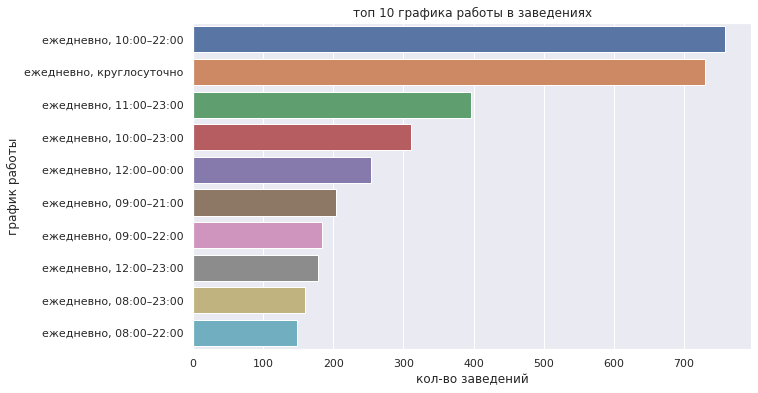

In [52]:
# построим сводную 
hours_count = df.pivot_table(
    index = 'hours',
    values = 'name',
    aggfunc = 'count').sort_values(by = 'name', ascending = False).reset_index().head(10)

display(hours_count)

# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'name', y = 'hours', data = hours_count)
plt.title('топ 10 графика работы в заведениях')
plt.xlabel('кол-во заведений')
plt.ylabel('график работы')

plt.show()

больше всего кафе с графиком работы  ежедневно, 10:00–22:00	758 шт. и ежедневно, круглосуточно	730.

In [53]:
# теперь разделим их на категории
hours_count_category = df.groupby(
    ['hours', 'category']).agg(
    count=('category', 'count')).sort_values(
    by = 'count', ascending = False).reset_index().head(10)


fig = px.bar(hours_count_category.sort_values(by='count', ascending=False), 
             x='count', 
             y='hours', 
             color='category')
fig.update_layout(title='Количество заведений каждой категории по графику работы',
                  xaxis_title='Количество заведений',
                  yaxis_title='график работы',
                  height=500,
                  width=1000,
                  xaxis={'categoryorder':'total descending'})
fig.show()

основная категория кафе 

In [54]:
# теперь разделим их округа
hours_count_category = df.groupby(
    ['hours', 'district']).agg(
    count=('district', 'count')).sort_values(
    by = 'count', ascending = False).reset_index().head(15)


fig = px.bar(hours_count_category.sort_values(by='count', ascending=False), 
             x='count', 
             y='hours', 
             color='district')
fig.update_layout(title='Количество заведений каждой категории по графику работы',
                  xaxis_title='Количество заведений',
                  yaxis_title='график работы',
                  height=500,
                  width=1000,
                  xaxis={'categoryorder':'total descending'})
fig.show()

большенство заведений в округах работают ежедневно с 10 до 12

#### Вывод:
 - часы работы заведений и их зависимость от расположения и категории заведения:
  - больше всего кафе с графиком работы ежедневно, 10:00–22:00 758 шт. и ежедневно, круглосуточно 730.
  - основная категория заведений это - кафе
  - большенство заведений в округах работают ежедневно с 10 до 12
  - по округам в цетре больше всего разнообразия графика работы заведений

### Вывод шаг 3


 - 1. Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по категориям: рестораны, кофейни, пиццерии, бары и так далее. Постройте визуализации. Ответьте на вопрос о распределении заведений по категориям.
    - Максимальное кол-во заведений в категории кафе 2376 шт.
    - Минимальное кол-во заведений в категории булочная 256 шт.
 - 2. Исследуйте количество посадочных мест в местах по категориям: рестораны, кофейни, пиццерии, бары и так далее. Постройте визуализации. Проанализируйте результаты и сделайте выводы.
    - Максимальное медианное кол-во посадочных мест в категории ресторан 86 шт.
    - Минимальное медианное кол-во посадочных мест в категории булочная 50 шт.
 - 3. Рассмотрите и изобразите соотношение сетевых и несетевых заведений в датасете. Каких заведений больше?
    - Максимальное кол-во заведений несетевых 5199 шт. 61,9%
    - Минимальное кол-во заведений сетевых 3203 шт. 38,1%
 - 4. Какие категории заведений чаще являются сетевыми? Исследуйте данные и ответьте на вопрос графиком.
    - Максимальное кол-во заведений сетевых в категории кафе 779 шт. это 9,27% от всех заведений в данных и 32,79% в этой категории
    - Минимальное кол-во заведений сетевых в категории столовая 88 шт. это 1,05% от всех заведений в данных и 61,33 в этой категории
 - 5. Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Под популярностью понимается количество заведений этой сети в регионе. Постройте подходящую для такой информации визуализацию. Знакомы ли вам эти сети? Есть ли какой-то признак, который их объединяет? К какой категории заведений они относятся?
     - Максимальное кол-во заведений сетевых в под названием шоколадница 120 шт.
     - Минимальное кол-во заведений сетевых в под названием му-му 27 шт.
     - Объединяет их всех - это быстрая еда
 - 6. Какие административные районы Москвы присутствуют в датасете? Отобразите общее количество заведений и количество заведений каждой категории по районам. Попробуйте проиллюстрировать эту информацию одним графиком.
     - Максимальное кол-во заведений в Центральный административный округ	2242. Большая часть это рестораны
     - Минимальное кол-во заведений Северо-Западный административный округ	409
 - 7. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги в разных типах общепита?
     - Максимальное рейтинг заведений в бар,паб	4.39 из 5
     - Минимальное рейтинг заведений быстрое питание	4.05 из 5
 - 8. Постройте фоновую картограмму (хороплет) со средним рейтингом заведений каждого района. Границы районов Москвы, которые встречаются в датасете, хранятся в файле admin_level_geomap.geojson (скачать файл для локальной работы).
      - Самый высокий рейтинг Центральный административный округ	4.38 из 5
      - Самый низкий рейтинг Юго-Восточный административный округ	4.10 из 5
 - 9. тобразите все заведения датасета на карте с помощью кластеров средствами библиотеки folium.
      - Все заведения нажодятся в пределах МКАДа
 - 10. Найдите топ-15 улиц по количеству заведений. Постройте график распределения количества заведений и их категорий по этим улицам. Попробуйте проиллюстрировать эту информацию одним графиком.
      - Максимальное кол-во заведений на улице - проспект мира	183 шт.
      - Минимальное кол-во заведений на улице пятницкая улица	48 шт.
      - Первые 5 улиц - это самые длиные улицы в Москве
 - 11. Найдите улицы, на которых находится только один объект общепита. Что можно сказать об этих заведениях?
      - Заведений 457 шт
      - Заведения расположены равномерно по карте москвы
      - По категориям больше всего кафе 159 шт
      - По округам больше всего находится заведенй в центре 153 шт.
      - Распределение больше несетевых 70,9%, а сетевых 29,1%
 - 12. Значения средних чеков заведений хранятся в столбце middle_avg_bill. Эти числа показывают примерную стоимость заказа в рублях, которая чаще всего выражена диапазоном. Посчитайте медиану этого столбца для каждого района. Используйте это значение в качестве ценового индикатора района. Постройте фоновую картограмму (хороплет) с полученными значениями для каждого района. Проанализируйте цены в центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях?
      - максимальный средний чек в центральном округе и западном 1000 
      - минимальный средний чек в юго-восточном округе 450.
 - 13. Необязательное задание: проиллюстрируйте другие взаимосвязи, которые вы нашли в данных. Например, по желанию исследуйте часы работы заведений и их зависимость от расположения и категории заведения. Также можно исследовать особенности заведений с плохими рейтингами, средние чеки в таких местах и распределение по категориям заведений.
     - часы работы заведений и их зависимость от расположения и категории заведения:
     - больше всего кафе с графиком работы ежедневно, 10:00–22:00 758 шт. и ежедневно, круглосуточно 730.
     - основная категория заведений это - кафе
     - большенство заведений в округах работают ежедневно с 10 до 12
     - по округам в цетре больше всего разнообразия графика работы заведений


## - Шаг 4. Детализируем исследование: открытие кофейни

### Сколько всего кофеен в датасете? В каких районах их больше всего, каковы особенности их расположения?

In [55]:
# отфильтруем только заведения с кофейнями
df_coffee = df.query("category == 'кофейня'")
display(df_coffee.head(5))

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,is_24_7
3,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.88,37.49,5.00,NaN,цена чашки капучино:155–185 ₽,NaN,170.00,несетевые,NaN,улица маршала федоренко,False
25,в парке вкуснее,кофейня,"москва, парк левобережный",Северный административный округ,"ежедневно, 10:00–21:00",55.88,37.46,4.30,NaN,NaN,NaN,NaN,сетевые,NaN,парк левобережный,False
45,9 bar coffee,кофейня,"москва, коровинское шоссе, 41, стр. 1",Северный административный округ,пн-пт 08:00–18:00,55.89,37.51,4.00,NaN,NaN,NaN,NaN,сетевые,46.00,коровинское шоссе,False
46,cofefest,кофейня,"москва, улица маршала федоренко, 6с1",Северный административный округ,пн-пт 09:00–19:00,55.88,37.49,3.60,NaN,NaN,NaN,NaN,сетевые,NaN,улица маршала федоренко,False
52,cofix,кофейня,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 08:00–22:00",55.88,37.48,3.80,NaN,NaN,NaN,NaN,сетевые,NaN,улица дыбенко,False


In [56]:
# посчитаем сколько кофеен
display('Всего кофеен в данных %d.' % (df_coffee['name'].count()))

'Всего кофеен в данных 1413.'

,district,name
0,Центральный административный округ,428
1,Северный административный округ,193
2,Северо-Восточный административный округ,159
3,Западный административный округ,150
4,Южный административный округ,131
5,Восточный административный округ,105
6,Юго-Западный административный округ,96
7,Юго-Восточный административный округ,89
8,Северо-Западный административный округ,62


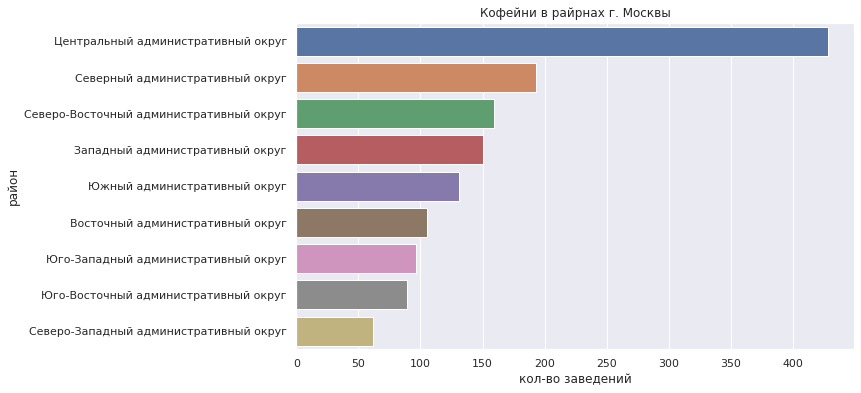

In [57]:
# построим сводную 
district_coffee = df_coffee.pivot_table(
    index = 'district',
    values = 'name',
    aggfunc = 'count').sort_values(by = 'name', ascending = False).reset_index()

display(district_coffee)


# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'name', y = 'district', data = district_coffee)
plt.title('Кофейни в райрнах г. Москвы')
plt.xlabel('кол-во заведений')
plt.ylabel('район')

plt.show()

In [58]:
# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
Choropleth(
    geo_data=state_geo,
    data=district_coffee,
    columns=['district', 'name'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Количество кофеен по районам',
).add_to(m)

# выводим карту
m

#### Вывод:
 - Сколько всего кофеен в датасете? 
   - Всего кофеен в данных 1413
 - Каких районах их больше всего?
   - Центральный административный округ	428
   - Северный административный округ	193
   - Северо-Восточный административный округ	159
   - Западный административный округ	150
   - Южный административный округ	131
   - Восточный административный округ	105
   - Юго-Западный административный округ	96
   - Юго-Восточный административный округ	89
   - Северо-Западный административный округ	62
 - Каковы особенности их расположения?
   - В каждом районе есть кофеейни, чем дальше от центра тем реже они встречаются
  

### Есть ли круглосуточные кофейни?

In [59]:
# перезапишим данные True, 'круглосуточные 24/7 и alse, 'некруглосуточные'
df_coffee['is_24_7'] = df_coffee['is_24_7'].replace(True, 'круглосуточные 24/7')
df_coffee['is_24_7'] = df_coffee['is_24_7'].replace(False, 'некруглосуточные')

# cоберем сводную
is_24_7 = df_coffee.pivot_table(
    index = 'is_24_7',
    values = 'name',
    aggfunc = 'count').sort_values(by = 'name', ascending = False).reset_index()


# переименнуем столбцы
is_24_7.columns = ['is_24_7', 'count']

# добавим столбец percent % доля от общего кол-ва
is_24_7['percent'] = is_24_7['count'] / is_24_7['count'].sum() * 100
is_24_7
display(is_24_7)

# построим пирог
fig = go.Figure(data=[go.Pie(labels=is_24_7['is_24_7'], values=is_24_7['count'])])
fig.update_layout(title='Соотношение "круглосуточных" и "некруглосуточных" заведений')
fig.show()

,is_24_7,count,percent
0,некруглосуточные,1354,95.82
1,круглосуточные 24/7,59,4.18


#### Вывод:
 - некруглосуточные	заведений  - 1354 шт.	95.82%
 - круглосуточные заведений 24/7	- 59 шт.	4.18%



### Какие у кофеен рейтинги? Как они распределяются по районам?

,district,rating
0,Центральный административный округ,4.34
1,Северо-Западный административный округ,4.33
2,Северный административный округ,4.29
3,Юго-Западный административный округ,4.28
4,Восточный административный округ,4.28
5,Южный административный округ,4.23
6,Юго-Восточный административный округ,4.23
7,Северо-Восточный административный округ,4.22
8,Западный административный округ,4.20


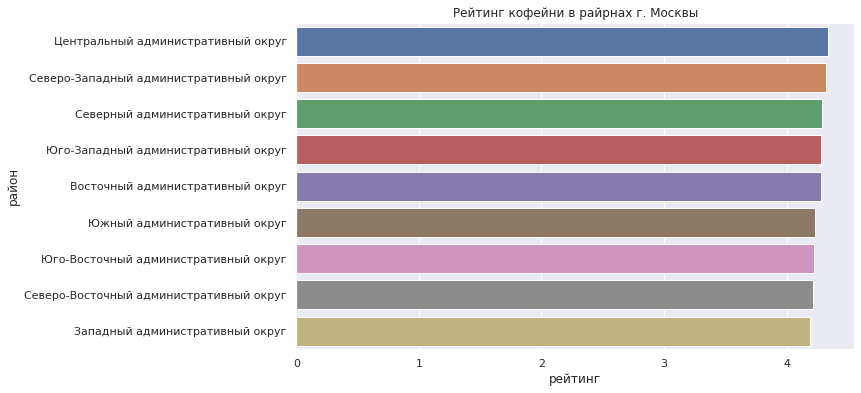

In [60]:
# построим сводную 
district_coffee_rating = df_coffee.pivot_table(
    index = 'district',
    values = 'rating',
    aggfunc = 'mean').sort_values(by = 'rating', ascending = False).reset_index()

display(district_coffee_rating)


# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'rating', y = 'district', data = district_coffee_rating)
plt.title('Рейтинг кофейни в райрнах г. Москвы')
plt.xlabel('рейтинг')
plt.ylabel('район')

plt.show()

#### Вывод:
 - Какие у кофеен рейтинги?
   - от 4,2 до 4,34 среднее значение
 - Как они распределяются по районам?
   - Лидер по рейтингу центральный район, самый низкий рейтинг в Западном раойне
 

### На какую стоимость чашки капучино стоит ориентироваться при открытии и почему?


,district,middle_coffee_cup
0,Юго-Западный административный округ,198.00
1,Центральный административный округ,190.00
2,Западный административный округ,189.00
3,Северо-Западный административный округ,165.00
4,Северо-Восточный административный округ,162.50
5,Северный административный округ,159.00
6,Южный административный округ,150.00
7,Юго-Восточный административный округ,147.50
8,Восточный административный округ,135.00


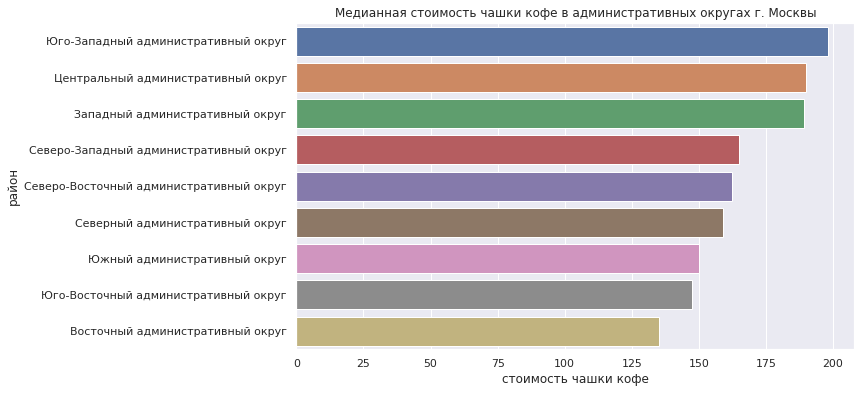

In [61]:
# построим сводную 
district_coffee_middle = df_coffee.pivot_table(
    index = 'district',
    values = 'middle_coffee_cup',
    aggfunc = 'median').sort_values(by = 'middle_coffee_cup', ascending = False).reset_index()

display(district_coffee_middle)


# настройка размера фигуры
plt.figure(figsize=(10, 6))

# построим гистограмму
sns.barplot(x = 'middle_coffee_cup', y = 'district', data = district_coffee_middle)
plt.title('Медианная стоимость чашки кофе в административных округах г. Москвы')
plt.xlabel('стоимость чашки кофе')
plt.ylabel('район')

plt.show()

#### Вывод: 
   - На какую стоимость чашки капучино стоит ориентироваться при открытии и почему?
 - Все завист от района открытия
   - 0	Юго-Западный административный округ	198.00
   - 1	Центральный административный округ	190.00
   - 2	Западный административный округ	189.00
   - 3	Северо-Западный административный округ	165.00
   - 4	Северо-Восточный административный округ	162.50
   - 5	Северный административный округ	159.00
   - 6	Южный административный округ	150.00
   - 7	Юго-Восточный административный округ	147.50
   - 8	Восточный административный округ	135.00

   

### Вывод шаг 4:

  - Сколько всего кофеен в датасете? В каких районах их больше всего, каковы особенности их расположения?
    - Сколько всего кофеен в датасете? 
      - Всего кофеен в данных 1413
    - Каких районах их больше всего?
      - Центральный административный округ	428
      - Северный административный округ	193
      - Северо-Восточный административный округ	159
      
     - Каковы особенности их расположения?
       - В каждом районе есть кофеейни, чем дальше от центра тем реже они встречаются
       
  - Есть ли круглосуточные кофейни?
     - некруглосуточные	заведений  - 1354 шт.	95.82%
     - круглосуточные заведений 24/7	- 59 шт.	4.18%
     
  - Какие у кофеен рейтинги? Как они распределяются по районам?
     - Какие у кофеен рейтинги?
       - от 4,2 до 4,34 среднее значение
     - Как они распределяются по районам?
       - Лидер по рейтингу центральный район, самый низкий рейтинг в Западном раойне
       
  - На какую стоимость чашки капучино стоит ориентироваться при открытии и почему?
  
    - Все завист от района открытия
      - 0	Юго-Западный административный округ	198.00
      - 1	Центральный административный округ	190.00
      - 2	Западный административный округ	189.00
      - 3	Северо-Западный административный округ	165.00
      - 4	Северо-Восточный административный округ	162.50
      - 5	Северный административный округ	159.00
      - 6	Южный административный округ	150.00
      - 7	Юго-Восточный административный округ	147.50
      - 8	Восточный административный округ	135.00


<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Добавила в самом конце 🙂
</div>

## - Шаг 5. Подготовка презентации

ссылка на презинтацию - https://disk.yandex.ru/i/5kxF7vO7KZ6iIg

## Общий вывод:
- Шаг 1. Загрузите данные и изучите общую информацию
  - Загрузили данные
 - Данные нормальные
 - Сколько заведений представлено? 
    - В данных 8406 заведений
 - Что можно сказать о каждом столбце?
    - Есть заведение не с полной информацие. Не полная информация может быть изза технических ошибок , возможно ручное введение данных.
 
 - Значения какого типа они хранят? 
    - В основном типы данных в текстовом формате
- Шаг 2. Выполните предобработку данных
    - Название столбцов не изменяли
 - Пропущеные обнаружены, удалять не будем, оставим как есть
     - Пропусков дастаточно много, просто удалить их не получится. осмотрим как их можно восполнить
     - Пропуски в hours, seats правильно заполнить не удастся, так как это индивидуальные данные для каждого заведения.
     - столбец price в разных административных округах имеет разное значение, и заполять пропуски в соответствии со значениями в столбце middle_avg_bill будет некорректным.
     - значения в столбце avg_bill распределены по столбцам middle_avg_bill и middle_coffee_cup.
 - Сделаем строчные буквы в столбцах
 - Обнаружили 4 неявных дубликатов, удалили их, на данные не повлияет
 - Добавили столбец street с названиями улиц из столбца с адресом
 - Добавили столбе is_24/7 с обозначением, что заведение работает ежедневно и круглосуточно (24/7)
 - Типы данных корректные
- Шаг 3. Анализ данных
   - 1. Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по категориям: рестораны, кофейни, пиццерии, бары и так далее. Постройте визуализации. Ответьте на вопрос о распределении заведений по категориям.
    - Максимальное кол-во заведений в категории кафе 2376 шт.
    - Минимальное кол-во заведений в категории булочная 256 шт.
 - 2. Исследуйте количество посадочных мест в местах по категориям: рестораны, кофейни, пиццерии, бары и так далее. Постройте визуализации. Проанализируйте результаты и сделайте выводы.
    - Максимальное медианное кол-во посадочных мест в категории ресторан 86 шт.
    - Минимальное медианное кол-во посадочных мест в категории булочная 50 шт.
 - 3. Рассмотрите и изобразите соотношение сетевых и несетевых заведений в датасете. Каких заведений больше?
    - Максимальное кол-во заведений несетевых 5199 шт. 61,9%
    - Минимальное кол-во заведений сетевых 3203 шт. 38,1%
 - 4. Какие категории заведений чаще являются сетевыми? Исследуйте данные и ответьте на вопрос графиком.
      - Максимальное кол-во заведений сетевых в категории кафе 779 шт. это 9,27% от всех заведений в данных и 32,79% в этой категории
      - Минимальное кол-во заведений сетевых в категории столовая 88 шт. это 1,05% от всех заведений в данных и 61,33 в этой категории
 - 5. Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Под популярностью понимается количество заведений этой сети в регионе. Постройте подходящую для такой информации визуализацию. Знакомы ли вам эти сети? Есть ли какой-то признак, который их объединяет? К какой категории заведений они относятся?
     - Максимальное кол-во заведений сетевых в под названием шоколадница 120 шт.
     - Минимальное кол-во заведений сетевых в под названием му-му 27 шт.
     - Объединяет их всех - это быстрая еда
 - 6. Какие административные районы Москвы присутствуют в датасете? Отобразите общее количество заведений и количество заведений каждой категории по районам. Попробуйте проиллюстрировать эту информацию одним графиком.
     - Максимальное кол-во заведений в Центральный административный округ	2242. Большая часть это рестораны
     - Минимальное кол-во заведений Северо-Западный административный округ	409
 - 7. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги в разных типах общепита?
     - Максимальное рейтинг заведений в бар,паб	4.39 из 5
     - Минимальное рейтинг заведений быстрое питание	4.05 из 5
 - 8. Постройте фоновую картограмму (хороплет) со средним рейтингом заведений каждого района. Границы районов Москвы, которые встречаются в датасете, хранятся в файле admin_level_geomap.geojson (скачать файл для локальной работы).
      - Самый высокий рейтинг Центральный административный округ	4.38 из 5
      - Самый низкий рейтинг Юго-Восточный административный округ	4.10 из 5
 - 9. тобразите все заведения датасета на карте с помощью кластеров средствами библиотеки folium.
      - Все заведения нажодятся в пределах МКАДа
 - 10. Найдите топ-15 улиц по количеству заведений. Постройте график распределения количества заведений и их категорий по этим улицам. Попробуйте проиллюстрировать эту информацию одним графиком.
      - Максимальное кол-во заведений на улице - проспект мира	183 шт.
      - Минимальное кол-во заведений на улице пятницкая улица	48 шт.
      - Первые 5 улиц - это самые длиные улицы в Москве
 - 11. Найдите улицы, на которых находится только один объект общепита. Что можно сказать об этих заведениях?
      - Заведений 457 шт
      - Заведения расположены равномерно по карте москвы
      - По категориям больше всего кафе 159 шт
      - По округам больше всего находится заведенй в центре 153 шт.
      - Распределение больше несетевых 70,9%, а сетевых 29,1%
 - 12. Значения средних чеков заведений хранятся в столбце middle_avg_bill. Эти числа показывают примерную стоимость заказа в рублях, которая чаще всего выражена диапазоном. Посчитайте медиану этого столбца для каждого района. Используйте это значение в качестве ценового индикатора района. Постройте фоновую картограмму (хороплет) с полученными значениями для каждого района. Проанализируйте цены в центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях?
      - максимальный средний чек в центральном округе и западном 1000 
      - минимальный средний чек в юго-восточном округе 450.
 - 13. Необязательное задание: проиллюстрируйте другие взаимосвязи, которые вы нашли в данных. Например, по желанию исследуйте часы работы заведений и их зависимость от расположения и категории заведения. Также можно исследовать особенности заведений с плохими рейтингами, средние чеки в таких местах и распределение по категориям заведений.
     - часы работы заведений и их зависимость от расположения и категории заведения:
     - больше всего кафе с графиком работы ежедневно, 10:00–22:00 758 шт. и ежедневно, круглосуточно 730.
     - основная категория заведений это - кафе
     - большенство заведений в округах работают ежедневно с 10 до 12
     - по округам в цетре больше всего разнообразия графика работы заведений

- Шаг 4. Детализируем исследование: открытие кофейни
    - Сколько всего кофеен в датасете? В каких районах их больше всего, каковы особенности их расположения?
    - Сколько всего кофеен в датасете? 
      - Всего кофеен в данных 1413
    - Каких районах их больше всего?
      - Центральный административный округ	428
      - Северный административный округ	193
      - Северо-Восточный административный округ	159
      
     - Каковы особенности их расположения?
       - В каждом районе есть кофеейни, чем дальше от центра тем реже они встречаются
       
  - Есть ли круглосуточные кофейни?
     - некруглосуточные	заведений  - 1354 шт.	95.82%
     - круглосуточные заведений 24/7	- 59 шт.	4.18%
     
  - Какие у кофеен рейтинги? Как они распределяются по районам?
     - Какие у кофеен рейтинги?
       - от 4,2 до 4,34 среднее значение
     - Как они распределяются по районам?
       - Лидер по рейтингу центральный район, самый низкий рейтинг в Западном раойне
       
  - На какую стоимость чашки капучино стоит ориентироваться при открытии и почему?
  
    - Все завист от района открытия
      - 0	Юго-Западный административный округ	198.00
      - 1	Центральный административный округ	190.00
      - 2	Западный административный округ	189.00
      - 3	Северо-Западный административный округ	165.00
      - 4	Северо-Восточный административный округ	162.50
      - 5	Северный административный округ	159.00
      - 6	Южный административный округ	150.00
      - 7	Юго-Восточный административный округ	147.50
      - 8	Восточный административный округ	135.00
      
- Шаг 5. Подготовка презентации
   - ссылка на презинтацию - https://disk.yandex.ru/i/5kxF7vO7KZ6iIg



## Рекомендации:
Рекомендую открыть кофейню в Юго-Западный административный округ, в этом округе самая высокая стоимость чашки кофе, так будет конкурентоспособность среди кофеен в этом районе, а так же в этом районе не так много кофеен по анализу данных. Средний чек в этом районе 600 руб это не максимальный и не самый минимальный по всем данным.